In [41]:
import sys

print("Versão do Python:", sys.version)

Versão do Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [42]:
import torch

print("Versão do PyTorch:", torch.__version__)
print("GPU disponível:", torch.cuda.is_available())

Versão do PyTorch: 2.14.1+cu130
GPU disponível: True


In [43]:
import cv2

print("Versão do OpenCV:", cv2.__version__)

Versão do OpenCV: 4.14.0


In [44]:
%pip install ultralytics

In [45]:
from ultralytics import YOLO

print("YOLO importado com sucesso!")

YOLO importado com sucesso!


In [46]:
from ultralytics import YOLO

modelo = YOLO("yolo11n.pt")

print("Modelo YOLO carregado com sucesso!")

Modelo YOLO carregado com sucesso!



Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 8.3ms
Speed: 2.0ms preprocess, 8.3ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 480)


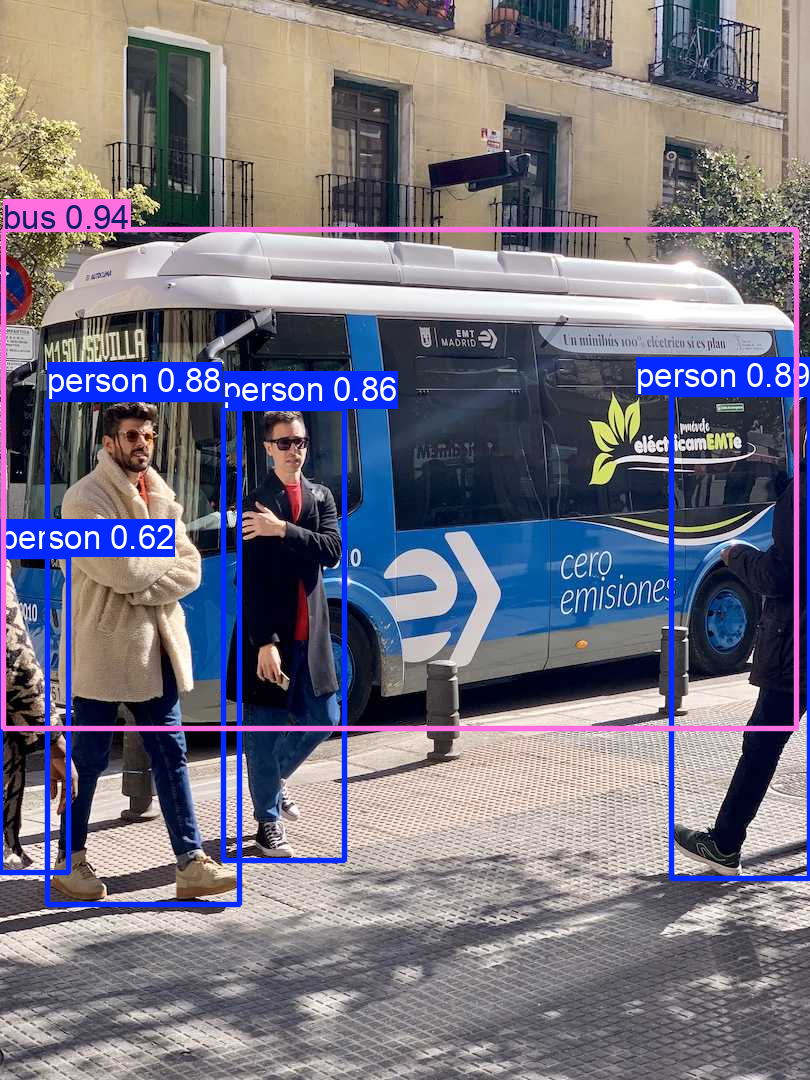

In [47]:
from IPython.display import display

resultados = modelo.predict(
    source="https://ultralytics.com/images/bus.jpg",
    conf=0.25
)

display(resultados[0].plot(pil=True))

In [48]:
import os

pastas = [
    "dataset/images/train",
    "dataset/images/val",
    "dataset/labels/train",
    "dataset/labels/val"
]

for pasta in pastas:
    os.makedirs(pasta, exist_ok=True)

print("Estrutura do dataset criada com sucesso!")

Estrutura do dataset criada com sucesso!


In [49]:
import os

arquivos = os.listdir("/content")

for arquivo in arquivos:
    if arquivo.lower().endswith((".jpg", ".jpeg", ".png")):
        print("Imagem encontrada:", arquivo)

Imagem encontrada: bus.jpg


In [50]:
from PIL import Image
from IPython.display import display

imagem = Image.open("/content/SIM-093-1.jpg")

print("Dimensões:", imagem.size)
display(imagem)

In [ ]:
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

cartaz = Image.new("RGB", (500, 700), "white")
desenho = ImageDraw.Draw(cartaz)

# Carregar fontes
fonte_titulo = ImageFont.load_default(size=35)
fonte_texto = ImageFont.load_default(size=22)

# Título
desenho.text((65, 35), "DESAPARECIDA", fill="red", font=fonte_titulo)

# Fotografia
foto = imagem.convert("RGB")
foto.thumbnail((350, 350))

x = (500 - foto.width) // 2
cartaz.paste(foto, (x, 110))

# Informações fictícias
desenho.text((145, 440), "CASO SIM-093", fill="black", font=fonte_texto)
desenho.text((95, 490), "VOCE TEM INFORMACOES?", fill="black", font=fonte_texto)
desenho.text((120, 550), "ELO DA BUSCA", fill="blue", font=fonte_texto)
desenho.text((105, 620), "SIMULACAO ACADEMICA", fill="gray", font=fonte_texto)

# Salvar e exibir
cartaz.save("/content/cartaz_SIM-093.jpg")

display(cartaz)

Fotografia recuperada com sucesso!


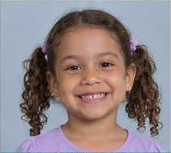

In [51]:
from PIL import Image
from IPython.display import display
import os

# Recuperar fotografia sintética do dataset
caminho = "/content/dataset/images/val/cartaz_val_000.jpg"

if os.path.exists(caminho):
    imagem_original = Image.open(caminho).convert("RGB")

    fotografia = imagem_original.crop((203, 273, 374, 426))

    print("Fotografia recuperada com sucesso!")
    display(fotografia)
else:
    print("Dataset não encontrado. Precisamos recuperá-lo do Drive.")

In [ ]:
from PIL import Image
from IPython.display import display

# Criar uma imagem de fundo
cenario = Image.new("RGB", (900, 700), "#b8b8b8")

# Abrir nosso cartaz
cartaz = Image.open("/content/cartaz_SIM-093.jpg")

# Redimensionar o cartaz
cartaz = cartaz.resize((300, 420))

# Posicionar o cartaz no cenário
x = 300
y = 140

cenario.paste(cartaz, (x, y))

# Salvar como imagem de treinamento
cenario.save("/content/dataset/images/train/cartaz_001.jpg")

# Mostrar resultado
display(cenario)

In [ ]:
# Dimensões da imagem
largura_imagem = 900
altura_imagem = 700

# Posição e dimensões do cartaz
x = 300
y = 140
largura_cartaz = 300
altura_cartaz = 420

# Calcular o centro do cartaz
centro_x = x + largura_cartaz / 2
centro_y = y + altura_cartaz / 2

# Normalizar as coordenadas
centro_x /= largura_imagem
centro_y /= altura_imagem
largura = largura_cartaz / largura_imagem
altura = altura_cartaz / altura_imagem

# Criar anotação YOLO
anotacao = f"0 {centro_x:.6f} {centro_y:.6f} {largura:.6f} {altura:.6f}"

# Salvar arquivo
caminho = "/content/dataset/labels/train/cartaz_001.txt"

with open(caminho, "w") as arquivo:
    arquivo.write(anotacao + "\n")

print("Anotação criada com sucesso!")
print(anotacao)

In [ ]:
from PIL import Image, ImageDraw
from IPython.display import display

# Abrir a imagem de treinamento
imagem_treino = Image.open(
    "/content/dataset/images/train/cartaz_001.jpg"
)

# Criar ferramenta de desenho
desenho = ImageDraw.Draw(imagem_treino)

# Coordenadas do cartaz
x1 = 300
y1 = 140
x2 = 600
y2 = 560

# Desenhar o retângulo
desenho.rectangle(
    [(x1, y1), (x2, y2)],
    outline="red",
    width=5
)

# Exibir resultado
display(imagem_treino)

In [ ]:
caminho = "/content/dataset/labels/train/cartaz_001.txt"

with open(caminho, "r") as arquivo:
    conteudo = arquivo.read()

print("Anotação YOLO:")
print(conteudo)

In [ ]:
import os
import random
from PIL import Image

random.seed(42)

cartaz_original = Image.open(
    "/content/cartaz_SIM-093.jpg"
).convert("RGB")

for i in range(20):
    largura_fundo = 900
    altura_fundo = 700

    fundo = Image.new(
        "RGB",
        (largura_fundo, altura_fundo),
        "#b8b8b8"
    )

    # Variar o tamanho do cartaz
    largura = random.randint(180, 350)
    altura = int(largura * 1.4)

    cartaz = cartaz_original.resize((largura, altura))

    # Variar a posição
    x = random.randint(0, largura_fundo - largura)
    y = random.randint(0, altura_fundo - altura)

    fundo.paste(cartaz, (x, y))

    # Calcular anotação YOLO
    centro_x = (x + largura / 2) / largura_fundo
    centro_y = (y + altura / 2) / altura_fundo

    largura_norm = largura / largura_fundo
    altura_norm = altura / altura_fundo

    nome = f"cartaz_auto_{i:03d}"

    fundo.save(
        f"/content/dataset/images/train/{nome}.jpg"
    )

    with open(
        f"/content/dataset/labels/train/{nome}.txt",
        "w"
    ) as arquivo:
        arquivo.write(
            f"0 {centro_x:.6f} {centro_y:.6f} "
            f"{largura_norm:.6f} {altura_norm:.6f}\n"
        )

print("20 imagens e 20 anotações criadas com sucesso!")

In [ ]:
from PIL import Image, ImageDraw
from IPython.display import display
import os

pasta = "/content/dataset/images/train"

# Selecionar três imagens geradas
nomes = [
    "cartaz_auto_000.jpg",
    "cartaz_auto_005.jpg",
    "cartaz_auto_010.jpg"
]

for nome in nomes:
    caminho = os.path.join(pasta, nome)
    imagem = Image.open(caminho)

    print(f"Imagem: {nome}")
    display(imagem)

In [ ]:
import os

pasta_imagens = "/content/dataset/images/train"
pasta_labels = "/content/dataset/labels/train"

imagens = sorted([
    nome for nome in os.listdir(pasta_imagens)
    if nome.endswith(".jpg")
])

erros = []

for nome in imagens:
    nome_label = os.path.splitext(nome)[0] + ".txt"
    caminho_label = os.path.join(pasta_labels, nome_label)

    if not os.path.exists(caminho_label):
        erros.append(f"Anotação ausente: {nome}")
        continue

    with open(caminho_label, "r") as arquivo:
        linhas = arquivo.readlines()

    for linha in linhas:
        valores = linha.split()

        if len(valores) != 5:
            erros.append(f"Formato inválido: {nome_label}")
            continue

        classe, x, y, largura, altura = map(float, valores)

        if (
            classe != 0
            or not 0 <= x - largura / 2
            or not x + largura / 2 <= 1
            or not 0 <= y - altura / 2
            or not y + altura / 2 <= 1
        ):
            erros.append(f"Coordenadas inválidas: {nome_label}")

print("Imagens encontradas:", len(imagens))
print("Erros encontrados:", len(erros))

for erro in erros:
    print(erro)

In [ ]:
import random
from PIL import Image

random.seed(123)

cores = [
    "#b8b8b8",  # Cinza
    "#d6c5a8",  # Bege
    "#8fa3ad",  # Azul acinzentado
    "#a8b59a",  # Verde claro
    "#795e50"   # Marrom
]

cartaz_original = Image.open(
    "/content/cartaz_SIM-093.jpg"
).convert("RGB")

for i in range(20):

    # Escolher uma cor de fundo
    cor = random.choice(cores)
    fundo = Image.new("RGB", (900, 700), cor)

    # Variar tamanho
    largura = random.randint(180, 350)
    altura = int(largura * 1.4)

    cartaz = cartaz_original.resize((largura, altura))

    # Variar posição
    x = random.randint(0, 900 - largura)
    y = random.randint(0, 700 - altura)

    fundo.paste(cartaz, (x, y))

    # Calcular coordenadas YOLO
    cx = (x + largura / 2) / 900
    cy = (y + altura / 2) / 700
    w = largura / 900
    h = altura / 700

    nome = f"cartaz_cores_{i:03d}"

    fundo.save(
        f"/content/dataset/images/train/{nome}.jpg"
    )

    with open(
        f"/content/dataset/labels/train/{nome}.txt", "w"
    ) as arquivo:
        arquivo.write(
            f"0 {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\n"
        )

print("20 novas imagens com fundos variados criadas!")

In [ ]:
from PIL import Image
from IPython.display import display

nomes = [
    "cartaz_cores_000.jpg",
    "cartaz_cores_005.jpg",
    "cartaz_cores_010.jpg"
]

for nome in nomes:
    caminho = f"/content/dataset/images/train/{nome}"

    imagem = Image.open(caminho)
    imagem.thumbnail((450, 350))

    print("Imagem:", nome)
    display(imagem)

In [ ]:
import os

arquivos = os.listdir("/content")

retratos = sorted([
    arquivo for arquivo in arquivos
    if arquivo.lower().endswith((".jpg", ".jpeg", ".png"))
    and arquivo.startswith("SIM-")
])

print("Retratos encontrados:", len(retratos))

for retrato in retratos:
    print(retrato)

In [ ]:
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
import os

os.makedirs("/content/cartazes", exist_ok=True)

fonte_titulo = ImageFont.load_default(size=32)
fonte_texto = ImageFont.load_default(size=20)

for arquivo in retratos:

    # Abrir o retrato
    foto = Image.open(f"/content/{arquivo}").convert("RGB")

    # Criar cartaz branco
    cartaz = Image.new("RGB", (500, 700), "white")
    desenho = ImageDraw.Draw(cartaz)

    # Obter identificação do caso
    codigo = arquivo.replace(".jpg", "").replace(".png", "")

    # Adicionar título
    desenho.text(
        (70, 35),
        "PESSOA DESAPARECIDA",
        fill="red",
        font=fonte_titulo
    )

    # Redimensionar fotografia
    foto.thumbnail((350, 350))

    x = (500 - foto.width) // 2
    y = 120

    cartaz.paste(foto, (x, y))

    # Adicionar informações
    desenho.text(
        (130, 490),
        f"CASO {codigo}",
        fill="black",
        font=fonte_texto
    )

    desenho.text(
        (100, 540),
        "ELO DA BUSCA",
        fill="blue",
        font=fonte_texto
    )

    desenho.text(
        (95, 620),
        "SIMULACAO ACADEMICA",
        fill="gray",
        font=fonte_texto
    )

    # Salvar cartaz
    caminho = f"/content/cartazes/cartaz_{codigo}.jpg"
    cartaz.save(caminho)

print("Cartazes criados:", len(retratos))

# Mostrar um exemplo
display(Image.open("/content/cartazes/cartaz_SIM-095-1.jpg"))

In [ ]:
import os
import random
from PIL import Image

random.seed(456)

pasta_cartazes = "/content/cartazes"

arquivos_cartazes = [
    arquivo for arquivo in os.listdir(pasta_cartazes)
    if arquivo.endswith(".jpg")
]

cores = [
    "#b8b8b8",
    "#d6c5a8",
    "#8fa3ad",
    "#a8b59a",
    "#795e50"
]

for i in range(60):

    # Escolher um cartaz aleatório
    arquivo = random.choice(arquivos_cartazes)

    cartaz = Image.open(
        os.path.join(pasta_cartazes, arquivo)
    ).convert("RGB")

    # Criar cenário
    fundo = Image.new(
        "RGB",
        (900, 700),
        random.choice(cores)
    )

    # Variar tamanho do cartaz
    largura = random.randint(180, 350)
    altura = int(largura * 1.4)

    cartaz = cartaz.resize((largura, altura))

    # Variar posição
    x = random.randint(0, 900 - largura)
    y = random.randint(0, 700 - altura)

    fundo.paste(cartaz, (x, y))

    # Coordenadas normalizadas para YOLO
    cx = (x + largura / 2) / 900
    cy = (y + altura / 2) / 700
    w = largura / 900
    h = altura / 700

    nome = f"cartaz_multi_{i:03d}"

    fundo.save(
        f"/content/dataset/images/train/{nome}.jpg"
    )

    with open(
        f"/content/dataset/labels/train/{nome}.txt",
        "w"
    ) as arquivo_label:
        arquivo_label.write(
            f"0 {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\n"
        )

print("60 novas imagens criadas com sucesso!")
print("Total esperado de treinamento: 101 imagens")

In [ ]:
import os

pasta = "/content/cartazes"

cartazes = sorted([
    nome for nome in os.listdir(pasta)
    if nome.endswith(".jpg")
])

print("Cartazes disponíveis:", len(cartazes))

for nome in cartazes:
    print(nome)

In [ ]:
import os
import random
from PIL import Image

random.seed(456)

pasta_cartazes = "/content/cartazes"

cartazes_train = sorted([
    nome for nome in os.listdir(pasta_cartazes)
    if nome.endswith(".jpg") and "SIM-097" not in nome
])

cartazes_val = sorted([
    nome for nome in os.listdir(pasta_cartazes)
    if nome.endswith(".jpg") and "SIM-097" in nome
])

print("Cartazes de treinamento:")
for nome in cartazes_train:
    print("-", nome)

print("\nCartazes de validação:")
for nome in cartazes_val:
    print("-", nome)

In [ ]:
import os
import glob

# Localizar somente as imagens geradas na etapa 6.28
imagens = glob.glob(
    "/content/dataset/images/train/cartaz_multi_*.jpg"
)

anotacoes = glob.glob(
    "/content/dataset/labels/train/cartaz_multi_*.txt"
)

print("Imagens encontradas:", len(imagens))
print("Anotações encontradas:", len(anotacoes))

# Remover os arquivos encontrados
for caminho in imagens + anotacoes:
    os.remove(caminho)

print("Arquivos antigos removidos com sucesso!")

# Conferir quantas imagens restaram
restantes = glob.glob(
    "/content/dataset/images/train/*.jpg"
)

print("Imagens de treinamento restantes:", len(restantes))

In [ ]:
import os
import random
from PIL import Image

random.seed(456)

cores = [
    "#b8b8b8",
    "#d6c5a8",
    "#8fa3ad",
    "#a8b59a",
    "#795e50"
]

for i in range(60):

    # Escolher somente cartazes de treinamento
    arquivo = random.choice(cartazes_train)

    cartaz = Image.open(
        f"/content/cartazes/{arquivo}"
    ).convert("RGB")

    # Criar fundo
    fundo = Image.new(
        "RGB",
        (900, 700),
        random.choice(cores)
    )

    # Variar tamanho
    largura = random.randint(180, 350)
    altura = int(largura * 1.4)

    cartaz = cartaz.resize((largura, altura))

    # Variar posição
    x = random.randint(0, 900 - largura)
    y = random.randint(0, 700 - altura)

    fundo.paste(cartaz, (x, y))

    # Coordenadas YOLO
    cx = (x + largura / 2) / 900
    cy = (y + altura / 2) / 700
    w = largura / 900
    h = altura / 700

    nome = f"cartaz_multi_{i:03d}"

    # Salvar imagem
    fundo.save(
        f"/content/dataset/images/train/{nome}.jpg"
    )

    # Salvar anotação
    with open(
        f"/content/dataset/labels/train/{nome}.txt",
        "w"
    ) as arquivo_label:
        arquivo_label.write(
            f"0 {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\n"
        )

print("60 imagens de treinamento criadas com sucesso!")

total = len([
    nome for nome in os.listdir("/content/dataset/images/train")
    if nome.endswith(".jpg")
])

print("Total de imagens de treinamento:", total)

In [ ]:
import os
import random
from PIL import Image

random.seed(789)

cores = [
    "#b8b8b8",
    "#d6c5a8",
    "#8fa3ad",
    "#a8b59a",
    "#795e50"
]

for i in range(20):

    # Escolher somente cartazes de validação
    arquivo = random.choice(cartazes_val)

    cartaz = Image.open(
        f"/content/cartazes/{arquivo}"
    ).convert("RGB")

    # Criar fundo
    fundo = Image.new(
        "RGB",
        (900, 700),
        random.choice(cores)
    )

    # Variar tamanho
    largura = random.randint(180, 350)
    altura = int(largura * 1.4)

    cartaz = cartaz.resize((largura, altura))

    # Variar posição
    x = random.randint(0, 900 - largura)
    y = random.randint(0, 700 - altura)

    fundo.paste(cartaz, (x, y))

    # Coordenadas normalizadas
    cx = (x + largura / 2) / 900
    cy = (y + altura / 2) / 700
    w = largura / 900
    h = altura / 700

    nome = f"cartaz_val_{i:03d}"

    # Salvar imagem de validação
    fundo.save(
        f"/content/dataset/images/val/{nome}.jpg"
    )

    # Salvar anotação
    with open(
        f"/content/dataset/labels/val/{nome}.txt",
        "w"
    ) as arquivo_label:
        arquivo_label.write(
            f"0 {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\n"
        )

print("20 imagens de validação criadas com sucesso!")

total_val = len([
    nome for nome in os.listdir("/content/dataset/images/val")
    if nome.endswith(".jpg")
])

print("Total de imagens de validação:", total_val)


In [ ]:
import os

conteudo = """
path: /content/dataset

train: images/train
val: images/val

nc: 1

names:
  0: cartaz_desaparecido
"""

caminho = "/content/dataset/data.yaml"

with open(caminho, "w", encoding="utf-8") as arquivo:
    arquivo.write(conteudo.strip() + "\n")

print("Arquivo data.yaml criado com sucesso!")
print()
print(open(caminho, encoding="utf-8").read())

In [ ]:
import os

for conjunto in ["train", "val"]:
    pasta_imagens = f"/content/dataset/images/{conjunto}"
    pasta_labels = f"/content/dataset/labels/{conjunto}"

    imagens = sorted([
        nome for nome in os.listdir(pasta_imagens)
        if nome.endswith(".jpg")
    ])

    labels = sorted([
        nome for nome in os.listdir(pasta_labels)
        if nome.endswith(".txt")
    ])

    sem_anotacao = [
        nome for nome in imagens
        if nome.replace(".jpg", ".txt") not in labels
    ]

    print(f"\nConjunto: {conjunto}")
    print("Imagens:", len(imagens))
    print("Anotações:", len(labels))
    print("Imagens sem anotação:", len(sem_anotacao))

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

In [ ]:
import os
import shutil

origem = "/content/dataset"

destino = "/content/drive/MyDrive/Elo_da_Busca/dataset"

# Criar a pasta no Google Drive
os.makedirs(os.path.dirname(destino), exist_ok=True)

# Copiar o dataset completo
shutil.copytree(origem, destino, dirs_exist_ok=True)

print("Backup realizado com sucesso!")
print("Local:", destino)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os

base = "/content/drive/MyDrive/Reencontra/dataset"

pastas = [
    "images/train",
    "images/val",
    "labels/train",
    "labels/val"
]

for pasta in pastas:
    caminho = os.path.join(base, pasta)
    print(f"{pasta}: {len(os.listdir(caminho))} arquivos")

print(
    "data.yaml existe:",
    os.path.isfile(os.path.join(base, "data.yaml"))
)

In [ ]:
import torch

print("Versão do PyTorch:", torch.__version__)
print("GPU disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Treinamento será realizado na CPU.")

In [ ]:
import torch

print("Versão do PyTorch:", torch.__version__)
print("GPU disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU ainda não disponível.")

In [ ]:
try:
    import ultralytics
    print("YOLO instalado!")
    print("Versão:", ultralytics.__version__)
except ImportError:
    print("YOLO precisa ser reinstalado.")

In [ ]:
%pip install ultralytics

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

In [ ]:
import os
import shutil

# Pasta de origem no Google Drive
origem = "/content/drive/MyDrive/Reencontra/dataset"

# Pasta de destino no Colab
destino = "/content/dataset"

# Copiar o dataset
shutil.copytree(origem, destino, dirs_exist_ok=True)

# Conferir os arquivos
print("Dataset recuperado com sucesso!")

for conjunto in ["train", "val"]:
    pasta = f"{destino}/images/{conjunto}"
    quantidade = len([
        nome for nome in os.listdir(pasta)
        if nome.endswith(".jpg")
    ])

    print(f"Imagens de {conjunto}: {quantidade}")

print("data.yaml encontrado:", os.path.isfile(
    f"{destino}/data.yaml"
))

In [ ]:
from ultralytics import YOLO

# Carregar o modelo pré-treinado
modelo = YOLO("yolo11n.pt")

# Iniciar o treinamento personalizado
resultados = modelo.train(
    data="/content/dataset/data.yaml",
    epochs=10,
    imgsz=640,
    batch=8,
    device=0,
    project="/content/drive/MyDrive/Reencontra/treinamentos",
    name="yolo_cartazes_v1",
    exist_ok=True
)

print("Treinamento finalizado!")

In [ ]:
import os

pasta = "/content/drive/MyDrive/Reencontra/treinamentos/yolo_cartazes_v1/weights"

print("Arquivos encontrados:")

if os.path.exists(pasta):
    for arquivo in os.listdir(pasta):
        print("-", arquivo)
else:
    print("Pasta ainda não encontrada.")

In [ ]:
from ultralytics import YOLO
from IPython.display import display
from PIL import Image
import glob

# Carregar nosso modelo treinado
modelo_reencontra = YOLO(
    "/content/drive/MyDrive/Reencontra/treinamentos/yolo_cartazes_v1/weights/best.pt"
)

# Selecionar uma imagem de validação
imagem_teste = sorted(
    glob.glob("/content/dataset/images/val/*.jpg")
)[0]

print("Imagem utilizada:", imagem_teste)

# Detectar o cartaz
resultados = modelo_reencontra.predict(
    source=imagem_teste,
    conf=0.25,
    device=0
)

# Mostrar a imagem com a detecção
imagem_resultado = resultados[0].plot()
display(Image.fromarray(imagem_resultado[:, :, ::-1]))

In [ ]:
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
import glob
import os

# 1. Criar pasta para os testes
os.makedirs("/content/testes_reencontra", exist_ok=True)

# 2. Criar imagem com fundo azul-claro
imagem = Image.new("RGB", (900, 700), "#DCEEF5")
desenho = ImageDraw.Draw(imagem)

# 3. Desenhar o cartaz
desenho.rounded_rectangle(
    (250, 70, 650, 630),
    radius=15,
    fill="white",
    outline="#164B73",
    width=5
)

# 4. Carregar fontes com segurança
try:
    fonte_titulo = ImageFont.truetype("DejaVuSans-Bold.ttf", 27)
    fonte_texto = ImageFont.truetype("DejaVuSans.ttf", 19)
except OSError:
    fonte_titulo = ImageFont.load_default(size=27)
    fonte_texto = ImageFont.load_default(size=19)

# 5. Escrever o novo nome do projeto
desenho.text(
    (345, 100),
    "REENCONTRA",
    fill="#164B73",
    font=fonte_titulo
)

desenho.text(
    (290, 155),
    "VOCE VIU ESTA PESSOA?",
    fill="#B42318",
    font=fonte_texto
)

# 6. Procurar um retrato sintético
retratos = sorted(glob.glob("/content/SIM-*.jpg"))

if retratos:
    retrato = Image.open(retratos[0]).convert("RGB")

    retrato.thumbnail((280, 280))

    x = 450 - retrato.width // 2
    y = 220

    imagem.paste(retrato, (x, y))

    print("Retrato utilizado:", retratos[0])
else:
    print("Aviso: nenhum retrato encontrado.")

# 7. Adicionar informações do cartaz
desenho.text(
    (330, 530),
    "CASO SIMULADO",
    fill="#164B73",
    font=fonte_texto
)

desenho.text(
    (290, 580),
    "PROJETO ACADEMICO",
    fill="#555555",
    font=fonte_texto
)

# 8. Salvar o novo cartaz
caminho_teste = "/content/testes_reencontra/cartaz_novo.jpg"

imagem.save(caminho_teste)

print("Cartaz criado com sucesso!")
print("Salvo em:", caminho_teste)

# 9. Exibir a imagem
display(imagem)

In [ ]:
from PIL import Image, ImageDraw
from IPython.display import display
import glob

# Buscar uma imagem de validação
arquivos = sorted(glob.glob("/content/dataset/images/val/*.jpg"))

# Abrir uma imagem existente
imagem_anterior = Image.open(arquivos[0]).convert("RGB")

# Recortar a região da fotografia sintética
# (coordenadas aproximadas do cartaz anterior)
print("Tamanho da imagem:", imagem_anterior.size)

display(imagem_anterior)

In [ ]:
from PIL import Image
from IPython.display import display

# 1. Recortar a fotografia do cartaz antigo
fotografia = imagem_anterior.crop((203, 273, 374, 426))

# 2. Abrir o novo cartaz do Reencontra
caminho = "/content/testes_reencontra/cartaz_novo.jpg"
cartaz = Image.open(caminho).convert("RGB")

# 3. Redimensionar a fotografia
fotografia = fotografia.resize((260, 230))

# 4. Inserir a fotografia no cartaz
cartaz.paste(fotografia, (320, 230))

# 5. Salvar a versão atualizada
cartaz.save(caminho)

print("Cartaz do Reencontra atualizado!")
display(cartaz)

In [ ]:
from ultralytics import YOLO
from PIL import Image
from IPython.display import display

# 1. Carregar o modelo personalizado
modelo = YOLO(
    "/content/drive/MyDrive/Reencontra/treinamentos/yolo_cartazes_v1/weights/best.pt"
)

# 2. Selecionar o novo cartaz
imagem_teste = "/content/testes_reencontra/cartaz_novo.jpg"

# 3. Executar a detecção
resultados = modelo.predict(
    source=imagem_teste,
    conf=0.25,
    device=0
)

# 4. Exibir o resultado com o retângulo
imagem_resultado = resultados[0].plot()

display(
    Image.fromarray(imagem_resultado[:, :, ::-1])
)

# 5. Mostrar quantos cartazes foram detectados
print("Cartazes detectados:", len(resultados[0].boxes))

In [ ]:
import os
import shutil

# Dataset original
origem = "/content/dataset"

# Novo dataset para a versão 2
destino = "/content/dataset_v2"

# Criar uma cópia sem alterar o original
shutil.copytree(
    origem,
    destino,
    dirs_exist_ok=True
)

# Conferir os arquivos copiados
for conjunto in ["train", "val"]:
    imagens = os.listdir(f"{destino}/images/{conjunto}")
    anotacoes = os.listdir(f"{destino}/labels/{conjunto}")

    imagens = [a for a in imagens if a.endswith(".jpg")]
    anotacoes = [a for a in anotacoes if a.endswith(".txt")]

    print(f"{conjunto}: {len(imagens)} imagens, {len(anotacoes)} anotações")

print("Dataset V2 criado com sucesso!")

In [ ]:
import os

# Pasta dos novos cartazes sintéticos
os.makedirs("/content/cartazes_v2", exist_ok=True)

# Pasta de testes independentes do treinamento
os.makedirs("/content/testes_v2", exist_ok=True)

print("Pastas preparadas com sucesso!")

print("Cartazes:", os.path.exists("/content/cartazes_v2"))
print("Testes:", os.path.exists("/content/testes_v2"))

In [ ]:
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
import os

# Recuperar fotografia sintética do dataset anterior
imagem_original = Image.open(
    "/content/dataset/images/val/cartaz_val_000.jpg"
).convert("RGB")

fotografia = imagem_original.crop((203, 273, 374, 426))
fotografia = fotografia.resize((230, 210))

# Configurar fontes
try:
    fonte_titulo = ImageFont.truetype("DejaVuSans-Bold.ttf", 25)
    fonte_texto = ImageFont.truetype("DejaVuSans.ttf", 17)
except OSError:
    fonte_titulo = ImageFont.load_default(size=25)
    fonte_texto = ImageFont.load_default(size=17)

# Definir os três estilos
estilos = [
    ("azul", "#174B78", "REENCONTRA"),
    ("laranja", "#D74A35", "PESSOA DESAPARECIDA"),
    ("verde", "#247456", "AJUDE A ENCONTRAR")
]

for nome, cor, titulo in estilos:

    # Criar cartaz
    cartaz = Image.new("RGB", (400, 560), "white")
    desenho = ImageDraw.Draw(cartaz)

    # Cabeçalho colorido
    desenho.rectangle((0, 0, 400, 90), fill=cor)

    # Centralizar título
    caixa = desenho.textbbox((0, 0), titulo, font=fonte_titulo)
    largura = caixa[2] - caixa[0]

    desenho.text(
        ((400 - largura) // 2, 30),
        titulo,
        fill="white",
        font=fonte_titulo
    )

    # Fotografia sintética
    cartaz.paste(fotografia, (85, 125))

    # Informações fictícias
    desenho.text(
        (105, 370),
        "CASO SIMULADO",
        fill=cor,
        font=fonte_texto
    )

    desenho.text(
        (75, 420),
        "PROJETO REENCONTRA",
        fill="black",
        font=fonte_texto
    )

    desenho.text(
        (75, 475),
        "SIMULACAO ACADEMICA",
        fill="#666666",
        font=fonte_texto
    )

    # Salvar cartaz
    caminho = f"/content/cartazes_v2/cartaz_{nome}.jpg"
    cartaz.save(caminho)

    print(f"Cartaz {nome} criado!")
    display(cartaz)

print("Os três estilos foram gerados com sucesso!")

In [ ]:
from PIL import Image
import os
import random

random.seed(42)

# Pastas do dataset V2
pasta_imagens = "/content/dataset_v2/images/train"
pasta_labels = "/content/dataset_v2/labels/train"

# Cartazes criados anteriormente
estilos = ["azul", "laranja", "verde"]

contador = 0

for estilo in estilos:

    caminho_cartaz = f"/content/cartazes_v2/cartaz_{estilo}.jpg"
    cartaz_original = Image.open(caminho_cartaz).convert("RGB")

    for i in range(20):

        # Criar fundo com cor aleatória
        cor_fundo = tuple(
            random.randint(100, 240) for _ in range(3)
        )

        imagem = Image.new("RGB", (900, 700), cor_fundo)

        # Variar o tamanho do cartaz
        largura = random.randint(200, 400)
        altura = int(largura * 560 / 400)

        cartaz = cartaz_original.resize((largura, altura))

        # Variar a posição
        x = random.randint(0, 900 - largura)
        y = random.randint(0, 700 - altura)

        imagem.paste(cartaz, (x, y))

        # Nome dos arquivos
        nome = f"cartaz_v2_{contador:03d}"

        imagem.save(f"{pasta_imagens}/{nome}.jpg")

        # Converter coordenadas para formato YOLO
        centro_x = (x + largura / 2) / 900
        centro_y = (y + altura / 2) / 700
        largura_norm = largura / 900
        altura_norm = altura / 700

        # Salvar anotação da classe 0
        with open(f"{pasta_labels}/{nome}.txt", "w") as arquivo:
            arquivo.write(
                f"0 {centro_x:.6f} {centro_y:.6f} "
                f"{largura_norm:.6f} {altura_norm:.6f}\n"
            )

        contador += 1

print("Novas imagens criadas:", contador)

print(
    "Total de imagens de treinamento:",
    len([
        a for a in os.listdir(pasta_imagens)
        if a.endswith(".jpg")
    ])
)

In [ ]:
from PIL import Image, ImageDraw
from IPython.display import display
import random
import os

# Selecionar três imagens novas
random.seed(10)

nomes = random.sample(
    [
        f for f in os.listdir("/content/dataset_v2/images/train")
        if f.startswith("cartaz_v2_") and f.endswith(".jpg")
    ],
    3
)

for nome in nomes:

    # Abrir imagem
    caminho_imagem = f"/content/dataset_v2/images/train/{nome}"
    imagem = Image.open(caminho_imagem).convert("RGB")

    largura, altura = imagem.size
    desenho = ImageDraw.Draw(imagem)

    # Abrir anotação correspondente
    caminho_label = (
        f"/content/dataset_v2/labels/train/"
        f"{nome.replace('.jpg', '.txt')}"
    )

    with open(caminho_label, "r") as arquivo:
        linhas = arquivo.readlines()

    for linha in linhas:
        classe, cx, cy, w, h = map(float, linha.split())

        # Converter coordenadas YOLO para pixels
        x1 = (cx - w / 2) * largura
        y1 = (cy - h / 2) * altura
        x2 = (cx + w / 2) * largura
        y2 = (cy + h / 2) * altura

        # Desenhar retângulo vermelho
        desenho.rectangle(
            (x1, y1, x2, y2),
            outline="red",
            width=5
        )

    print("Imagem:", nome)
    display(imagem)

In [ ]:
from PIL import Image, ImageDraw
import os
import random

random.seed(123)

pasta_imagens = "/content/dataset_v2/images/train"
pasta_labels = "/content/dataset_v2/labels/train"

# Utilizar a fotografia sintética já recuperada
fotografia = imagem_original.crop((203, 273, 374, 426))

for i in range(20):

    # Criar fundo colorido
    cor = tuple(random.randint(100, 230) for _ in range(3))
    imagem = Image.new("RGB", (900, 700), cor)

    # Variar o tamanho da fotografia
    largura = random.randint(150, 350)
    altura = random.randint(150, 350)

    foto = fotografia.resize((largura, altura))

    # Posicionar a fotografia aleatoriamente
    x = random.randint(0, 900 - largura)
    y = random.randint(0, 700 - altura)

    imagem.paste(foto, (x, y))

    nome = f"negativo_v2_{i:03d}"

    # Salvar imagem
    imagem.save(f"{pasta_imagens}/{nome}.jpg")

    # Anotação vazia: não existe cartaz na imagem
    open(f"{pasta_labels}/{nome}.txt", "w").close()

print("20 imagens negativas criadas!")

total = len([
    a for a in os.listdir(pasta_imagens)
    if a.endswith(".jpg")
])

print("Total de imagens de treinamento:", total)

In [ ]:
import yaml
import os

# Caminho da configuração do dataset V2
caminho_yaml = "/content/dataset_v2/data.yaml"

# Configuração para o novo treinamento
configuracao = {
    "path": "/content/dataset_v2",
    "train": "images/train",
    "val": "images/val",
    "nc": 1,
    "names": {
        0: "cartaz_desaparecido"
    }
}

# Atualizar arquivo
with open(caminho_yaml, "w", encoding="utf-8") as arquivo:
    yaml.safe_dump(
        configuracao,
        arquivo,
        allow_unicode=True,
        sort_keys=False
    )

# Conferir configuração
with open(caminho_yaml, "r", encoding="utf-8") as arquivo:
    print(arquivo.read())

print("Dataset V2 configurado com sucesso!")

In [ ]:
import shutil
import os

# Origem: dataset V2 no Colab
origem = "/content/dataset_v2"

# Destino: Google Drive
destino = "/content/drive/MyDrive/Reencontra/dataset_v2"

# Copiar o dataset completo
shutil.copytree(
    origem,
    destino,
    dirs_exist_ok=True,
    ignore=shutil.ignore_patterns("*.cache")
)

# Conferir os arquivos salvos
for conjunto in ["train", "val"]:
    imagens = [
        arquivo for arquivo in os.listdir(
            f"{destino}/images/{conjunto}"
        )
        if arquivo.endswith(".jpg")
    ]

    anotacoes = [
        arquivo for arquivo in os.listdir(
            f"{destino}/labels/{conjunto}"
        )
        if arquivo.endswith(".txt")
    ]

    print(
        f"{conjunto}: {len(imagens)} imagens, "
        f"{len(anotacoes)} anotações"
    )

print("Dataset V2 salvo no Google Drive!")

In [ ]:
import os
import shutil

# Pasta permanente dos testes
pasta_testes = "/content/drive/MyDrive/Reencontra/testes"

os.makedirs(pasta_testes, exist_ok=True)

# Cartaz que apresentou detecções incorretas no V1
origem = "/content/testes_reencontra/cartaz_novo.jpg"

destino = f"{pasta_testes}/cartaz_reencontra_teste.jpg"

# Salvar cópia no Google Drive
shutil.copy2(origem, destino)

print("Imagem de teste salva com sucesso!")
print("Caminho:", destino)
print("Arquivo existe:", os.path.isfile(destino))

In [ ]:
from PIL import Image
import os
import random

random.seed(2026)

# Pasta de testes no Google Drive
pasta = "/content/drive/MyDrive/Reencontra/testes/negativos"
os.makedirs(pasta, exist_ok=True)

# Fotografia sintética já recuperada
fotografia = imagem_original.crop((203, 273, 374, 426))

for i in range(5):

    # Criar um fundo diferente
    cor = tuple(random.randint(80, 220) for _ in range(3))
    imagem = Image.new("RGB", (900, 700), cor)

    # Variar o tamanho da fotografia
    largura = random.randint(180, 360)
    altura = random.randint(180, 360)

    foto = fotografia.resize((largura, altura))

    # Posicionar aleatoriamente
    x = random.randint(0, 900 - largura)
    y = random.randint(0, 700 - altura)

    imagem.paste(foto, (x, y))

    # Salvar imagem de teste
    caminho = f"{pasta}/negativo_teste_{i:03d}.jpg"
    imagem.save(caminho)

print("5 imagens negativas de teste criadas!")
print("Arquivos:", len(os.listdir(pasta)))

In [ ]:
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
import os

# Criar imagem de teste
imagem = Image.new("RGB", (900, 700), "#C8D3DA")
desenho = ImageDraw.Draw(imagem)

# Cartaz horizontal
desenho.rectangle(
    (100, 150, 800, 550),
    fill="white",
    outline="#222222",
    width=5
)

# Cabeçalho preto
desenho.rectangle(
    (100, 150, 800, 225),
    fill="#202020"
)

# Faixa amarela
desenho.rectangle(
    (100, 225, 800, 245),
    fill="#F5C542"
)

# Configurar fontes
try:
    titulo = ImageFont.truetype("DejaVuSans-Bold.ttf", 30)
    texto = ImageFont.truetype("DejaVuSans.ttf", 21)
except OSError:
    titulo = ImageFont.load_default(size=30)
    texto = ImageFont.load_default(size=21)

# Título
desenho.text(
    (280, 170),
    "REENCONTRA",
    fill="white",
    font=titulo
)

# Fotografia sintética
foto = fotografia.copy()
foto = foto.resize((210, 240))
imagem.paste(foto, (135, 270))

# Informações
desenho.text(
    (385, 285),
    "PESSOA DESAPARECIDA",
    fill="#B42318",
    font=texto
)

desenho.text(
    (385, 350),
    "CASO SIMULADO",
    fill="#222222",
    font=texto
)

desenho.text(
    (385, 410),
    "AJUDE A ENCONTRAR",
    fill="#222222",
    font=texto
)

desenho.text(
    (385, 470),
    "PROJETO ACADEMICO",
    fill="#555555",
    font=texto
)

# Salvar no Google Drive
pasta = "/content/drive/MyDrive/Reencontra/testes"
os.makedirs(pasta, exist_ok=True)

caminho = f"{pasta}/cartaz_horizontal_teste.jpg"
imagem.save(caminho)

print("Novo cartaz de teste criado!")
print("Arquivo:", caminho)

display(imagem)

In [ ]:
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
import os

# Criar imagem de teste
imagem = Image.new("RGB", (900, 700), "#C8D3DA")
desenho = ImageDraw.Draw(imagem)

# Cartaz horizontal
desenho.rectangle(
    (100, 150, 800, 550),
    fill="white",
    outline="#222222",
    width=5
)

# Cabeçalho preto
desenho.rectangle(
    (100, 150, 800, 225),
    fill="#202020"
)

# Faixa amarela
desenho.rectangle(
    (100, 225, 800, 245),
    fill="#F5C542"
)

# Configurar fontes
try:
    titulo = ImageFont.truetype("DejaVuSans-Bold.ttf", 30)
    texto = ImageFont.truetype("DejaVuSans.ttf", 21)
except OSError:
    titulo = ImageFont.load_default(size=30)
    texto = ImageFont.load_default(size=21)

# Título
desenho.text(
    (280, 170),
    "REENCONTRA",
    fill="white",
    font=titulo
)

# Fotografia sintética
foto = fotografia.copy()
foto = foto.resize((210, 240))
imagem.paste(foto, (135, 270))

# Informações
desenho.text(
    (385, 285),
    "PESSOA DESAPARECIDA",
    fill="#B42318",
    font=texto
)

desenho.text(
    (385, 350),
    "CASO SIMULADO",
    fill="#222222",
    font=texto
)

desenho.text(
    (385, 410),
    "AJUDE A ENCONTRAR",
    fill="#222222",
    font=texto
)

desenho.text(
    (385, 470),
    "PROJETO ACADEMICO",
    fill="#555555",
    font=texto
)

# Salvar no Google Drive
pasta = "/content/drive/MyDrive/Reencontra/testes"
os.makedirs(pasta, exist_ok=True)

caminho = f"{pasta}/cartaz_horizontal_teste.jpg"
imagem.save(caminho)

print("Novo cartaz de teste criado!")
print("Arquivo:", caminho)

display(imagem)

In [ ]:
from ultralytics import YOLO

# Carregar os pesos pré-treinados do YOLO11 Nano
modelo_v2 = YOLO("yolo11n.pt")

# Treinar com o dataset melhorado
resultados_v2 = modelo_v2.train(
    data="/content/dataset_v2/data.yaml",
    epochs=20,
    imgsz=640,
    batch=8,
    device=0,
    project="/content/drive/MyDrive/Reencontra/treinamentos",
    name="yolo_cartazes_v2",
    exist_ok=True
)

print("Treinamento V2 finalizado!")

In [ ]:
from ultralytics import YOLO
from PIL import Image
from IPython.display import display

# Carregar o modelo V2
modelo_v2 = YOLO(
    "/content/drive/MyDrive/Reencontra/treinamentos/yolo_cartazes_v2/weights/best.pt"
)

# Imagem que apresentou problemas no V1
imagem_teste = (
    "/content/drive/MyDrive/Reencontra/testes/"
    "cartaz_reencontra_teste.jpg"
)

# Executar detecção
resultados = modelo_v2.predict(
    source=imagem_teste,
    conf=0.25,
    device=0
)

# Mostrar resultado
imagem_resultado = resultados[0].plot()
display(Image.fromarray(imagem_resultado[:, :, ::-1]))

# Mostrar quantidade de detecções
print("Cartazes detectados:", len(resultados[0].boxes))

In [ ]:
from PIL import Image
from IPython.display import display

# Cartaz horizontal criado anteriormente
imagem_horizontal = (
    "/content/drive/MyDrive/Reencontra/testes/"
    "cartaz_horizontal_teste.jpg"
)

# Utilizar o YOLO V2 já carregado
resultado_horizontal = modelo_v2.predict(
    source=imagem_horizontal,
    conf=0.25,
    device=0
)

# Exibir imagem com as detecções
imagem_detectada = resultado_horizontal[0].plot()

display(
    Image.fromarray(imagem_detectada[:, :, ::-1])
)

# Mostrar quantidade de detecções
print(
    "Cartazes detectados:",
    len(resultado_horizontal[0].boxes)
)

In [ ]:
import glob
from PIL import Image
from IPython.display import display

# Buscar as cinco imagens negativas
imagens = sorted(glob.glob(
    "/content/drive/MyDrive/Reencontra/testes/negativos/*.jpg"
))

total_deteccoes = 0

for caminho in imagens:

    # Executar o YOLO V2
    resultado = modelo_v2.predict(
        source=caminho,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    quantidade = len(resultado.boxes)
    total_deteccoes += quantidade

    print(f"\nImagem: {caminho.split('/')[-1]}")
    print(f"Detecções incorretas: {quantidade}")

    # Mostrar resultado
    imagem = resultado.plot()
    display(Image.fromarray(imagem[:, :, ::-1]))

print("\nTotal de detecções incorretas:", total_deteccoes)

In [ ]:
import shutil
import os

# Dataset V2 original
origem = "/content/dataset_v2"

# Novo dataset V3
destino = "/content/dataset_v3"

# Copiar sem modificar o V2
shutil.copytree(
    origem,
    destino,
    dirs_exist_ok=True,
    ignore=shutil.ignore_patterns("*.cache")
)

# Conferir arquivos
for conjunto in ["train", "val"]:
    imagens = [
        a for a in os.listdir(f"{destino}/images/{conjunto}")
        if a.endswith(".jpg")
    ]

    anotacoes = [
        a for a in os.listdir(f"{destino}/labels/{conjunto}")
        if a.endswith(".txt")
    ]

    print(
        f"{conjunto}: {len(imagens)} imagens, "
        f"{len(anotacoes)} anotações"
    )

print("Dataset V3 preparado com sucesso!")

Cartaz horizontal azul criado!


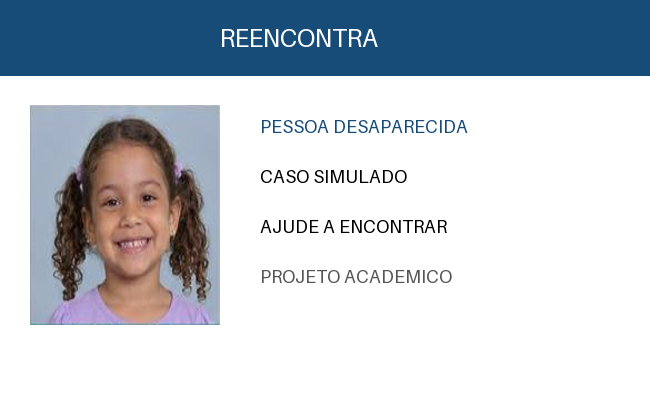

Cartaz horizontal laranja criado!


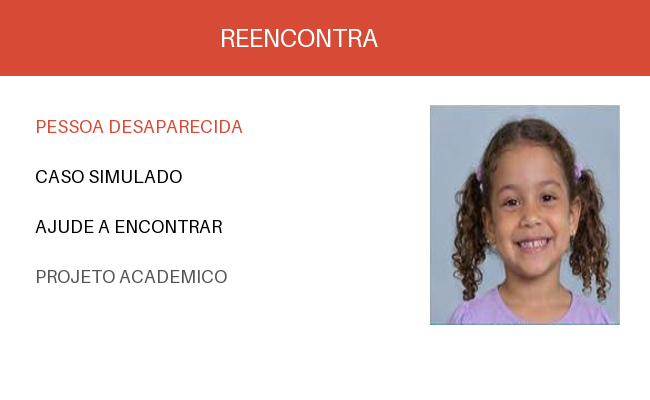

Cartaz horizontal verde criado!


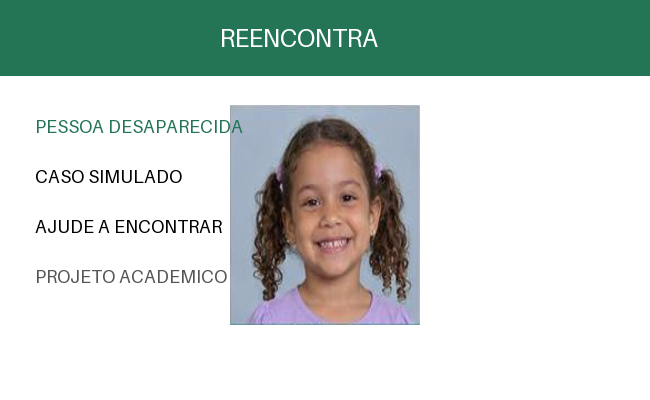

Três cartazes horizontais criados!


In [52]:
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
import os

# Pasta dos cartazes horizontais
pasta = "/content/cartazes_horizontais_v3"
os.makedirs(pasta, exist_ok=True)

# Fotografia sintética já utilizada no projeto
foto = fotografia.copy().convert("RGB")
foto = foto.resize((190, 220))

# Fontes
try:
    fonte_titulo = ImageFont.truetype("DejaVuSans-Bold.ttf", 25)
    fonte_texto = ImageFont.truetype("DejaVuSans.ttf", 18)
except OSError:
    fonte_titulo = ImageFont.load_default(size=25)
    fonte_texto = ImageFont.load_default(size=18)

# Estilos: nome, cor, posição da foto
estilos = [
    ("azul", "#174B78", "esquerda"),
    ("laranja", "#D74A35", "direita"),
    ("verde", "#247456", "centro")
]

for nome, cor, posicao in estilos:

    cartaz = Image.new("RGB", (650, 400), "white")
    desenho = ImageDraw.Draw(cartaz)

    # Cabeçalho
    desenho.rectangle((0, 0, 650, 75), fill=cor)

    desenho.text(
        (220, 22),
        "REENCONTRA",
        fill="white",
        font=fonte_titulo
    )

    # Posição da fotografia e dos textos
    if posicao == "esquerda":
        x_foto = 30
        x_texto = 260

    elif posicao == "direita":
        x_foto = 430
        x_texto = 35

    else:
        x_foto = 230
        x_texto = 35

    cartaz.paste(foto, (x_foto, 105))

    # Informações fictícias
    desenho.text(
        (x_texto, 115),
        "PESSOA DESAPARECIDA",
        fill=cor,
        font=fonte_texto
    )

    desenho.text(
        (x_texto, 165),
        "CASO SIMULADO",
        fill="black",
        font=fonte_texto
    )

    desenho.text(
        (x_texto, 215),
        "AJUDE A ENCONTRAR",
        fill="black",
        font=fonte_texto
    )

    desenho.text(
        (x_texto, 265),
        "PROJETO ACADEMICO",
        fill="#555555",
        font=fonte_texto
    )

    # Salvar
    caminho = f"{pasta}/horizontal_{nome}.jpg"
    cartaz.save(caminho)

    print(f"Cartaz horizontal {nome} criado!")
    display(cartaz)

print("Três cartazes horizontais criados!")


Cartaz horizontal: AZUL


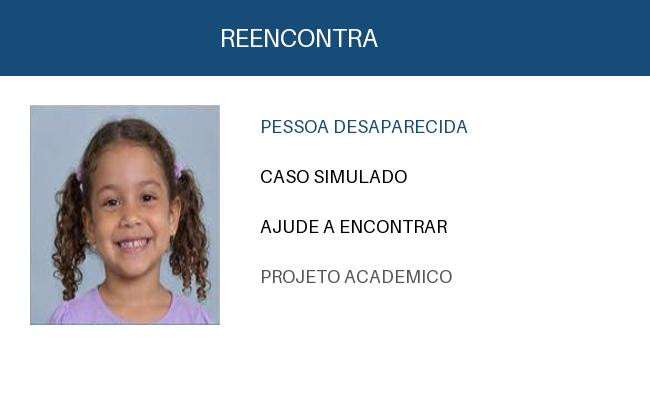


Cartaz horizontal: LARANJA


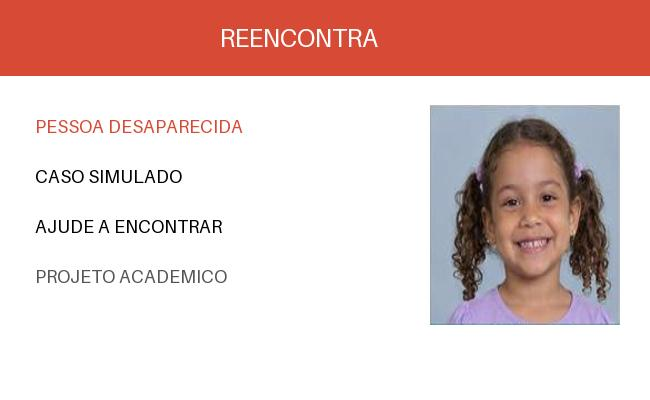


Cartaz horizontal: VERDE


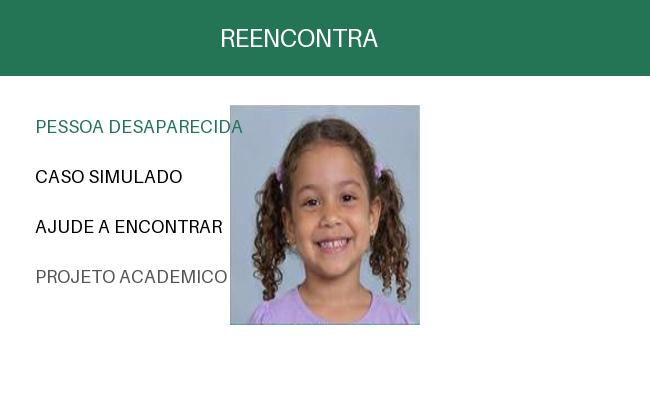

In [53]:
from PIL import Image
from IPython.display import display
import os

pasta = "/content/cartazes_horizontais_v3"

for estilo in ["azul", "laranja", "verde"]:
    caminho = f"{pasta}/horizontal_{estilo}.jpg"

    if os.path.exists(caminho):
        print(f"\nCartaz horizontal: {estilo.upper()}")
        display(Image.open(caminho))
    else:
        print(f"Arquivo não encontrado: {caminho}")

Cartaz verde corrigido com sucesso!


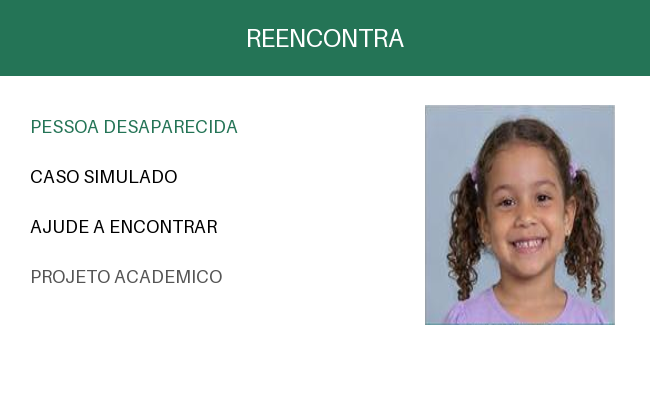

In [54]:
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# Criar novamente somente o cartaz verde
cartaz = Image.new("RGB", (650, 400), "white")
desenho = ImageDraw.Draw(cartaz)

cor = "#247456"

# Cabeçalho verde
desenho.rectangle((0, 0, 650, 75), fill=cor)

# Título centralizado
titulo = "REENCONTRA"
caixa = desenho.textbbox((0, 0), titulo, font=fonte_titulo)
largura_titulo = caixa[2] - caixa[0]

desenho.text(
    ((650 - largura_titulo) // 2, 22),
    titulo,
    fill="white",
    font=fonte_titulo
)

# Fotografia à direita, sem sobrepor textos
cartaz.paste(foto, (425, 105))

# Informações à esquerda
desenho.text(
    (30, 115),
    "PESSOA DESAPARECIDA",
    fill=cor,
    font=fonte_texto
)

desenho.text(
    (30, 165),
    "CASO SIMULADO",
    fill="black",
    font=fonte_texto
)

desenho.text(
    (30, 215),
    "AJUDE A ENCONTRAR",
    fill="black",
    font=fonte_texto
)

desenho.text(
    (30, 265),
    "PROJETO ACADEMICO",
    fill="#555555",
    font=fonte_texto
)

# Salvar por cima do cartaz verde anterior
caminho = "/content/cartazes_horizontais_v3/horizontal_verde.jpg"
cartaz.save(caminho)

print("Cartaz verde corrigido com sucesso!")
display(cartaz)

In [55]:
from PIL import Image
import os
import random

random.seed(2026)

pasta_cartazes = "/content/cartazes_horizontais_v3"
pasta_imagens = "/content/dataset_v3/images/train"
pasta_labels = "/content/dataset_v3/labels/train"

estilos = ["azul", "laranja", "verde"]

contador = 0

for estilo in estilos:

    caminho = f"{pasta_cartazes}/horizontal_{estilo}.jpg"
    cartaz_original = Image.open(caminho).convert("RGB")

    for i in range(20):

        # Criar fundo com cor aleatória
        cor_fundo = tuple(
            random.randint(90, 230) for _ in range(3)
        )

        imagem = Image.new("RGB", (900, 700), cor_fundo)

        # Variar tamanho, mantendo a proporção horizontal
        largura = random.randint(350, 750)
        altura = round(largura * 400 / 650)

        cartaz = cartaz_original.resize((largura, altura))

        # Posicionar o cartaz aleatoriamente
        x = random.randint(0, 900 - largura)
        y = random.randint(0, 700 - altura)

        imagem.paste(cartaz, (x, y))

        # Nome exclusivo para cada imagem
        nome = f"horizontal_v3_{contador:03d}"

        imagem.save(
            f"{pasta_imagens}/{nome}.jpg"
        )

        # Coordenadas no formato YOLO
        centro_x = (x + largura / 2) / 900
        centro_y = (y + altura / 2) / 700
        largura_norm = largura / 900
        altura_norm = altura / 700

        # Classe 0 = cartaz_desaparecido
        with open(
            f"{pasta_labels}/{nome}.txt", "w"
        ) as arquivo:
            arquivo.write(
                f"0 {centro_x:.6f} {centro_y:.6f} "
                f"{largura_norm:.6f} {altura_norm:.6f}\n"
            )

        contador += 1

print("Novas imagens horizontais:", contador)

total = len([
    arquivo for arquivo in os.listdir(pasta_imagens)
    if arquivo.endswith(".jpg")
])

print("Total de imagens de treinamento:", total)

Novas imagens horizontais: 60
Total de imagens de treinamento: 241


In [56]:
import os
import shutil

# Dataset V3 no Colab
origem = "/content/dataset_v3"

# Destino no Google Drive
destino = "/content/drive/MyDrive/Reencontra/dataset_v3"

# Salvar todos os arquivos
shutil.copytree(
    origem,
    destino,
    dirs_exist_ok=True,
    ignore=shutil.ignore_patterns("*.cache")
)

# Conferir se tudo foi salvo
for conjunto in ["train", "val"]:
    imagens = [
        a for a in os.listdir(f"{destino}/images/{conjunto}")
        if a.endswith(".jpg")
    ]

    anotacoes = [
        a for a in os.listdir(f"{destino}/labels/{conjunto}")
        if a.endswith(".txt")
    ]

    print(
        f"{conjunto}: {len(imagens)} imagens, "
        f"{len(anotacoes)} anotações"
    )

print("data.yaml salvo:", os.path.isfile(f"{destino}/data.yaml"))
print("Dataset V3 salvo no Google Drive!")

train: 241 imagens, 241 anotações
val: 20 imagens, 20 anotações
data.yaml salvo: True
Dataset V3 salvo no Google Drive!


In [1]:
import torch

print("PyTorch:", torch.__version__)
print("GPU disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
GPU disponível: True
GPU: Tesla T4


In [2]:
from google.colab import drive
import os

drive.mount('/content/drive')

caminho = "/content/drive/MyDrive/Reencontra/dataset_v3"

print("Dataset V3 encontrado:", os.path.exists(caminho))

if os.path.exists(caminho):
    print("Arquivos:", os.listdir(caminho))

Mounted at /content/drive
Dataset V3 encontrado: True
Arquivos: ['images', 'data.yaml', 'labels']


In [3]:
import shutil
import os

# Pasta salva no Google Drive
origem = "/content/drive/MyDrive/Reencontra/dataset_v3"

# Pasta de trabalho do Colab
destino = "/content/dataset_v3"

# Restaurar o dataset
shutil.copytree(origem, destino, dirs_exist_ok=True)

# Conferir os arquivos
for conjunto in ["train", "val"]:
    imagens = os.listdir(f"{destino}/images/{conjunto}")
    anotacoes = os.listdir(f"{destino}/labels/{conjunto}")

    print(f"{conjunto}: {len(imagens)} imagens, {len(anotacoes)} anotações")

print("Dataset V3 restaurado com sucesso!")

train: 241 imagens, 241 anotações
val: 20 imagens, 20 anotações
Dataset V3 restaurado com sucesso!


In [4]:
import yaml

caminho_yaml = "/content/dataset_v3/data.yaml"

configuracao = {
    "path": "/content/dataset_v3",
    "train": "images/train",
    "val": "images/val",
    "nc": 1,
    "names": {
        0: "cartaz_desaparecido"
    }
}

with open(caminho_yaml, "w") as arquivo:
    yaml.safe_dump(
        configuracao,
        arquivo,
        sort_keys=False,
        allow_unicode=True
    )

# Conferir o conteúdo
with open(caminho_yaml, "r") as arquivo:
    print(arquivo.read())

path: /content/dataset_v3
train: images/train
val: images/val
nc: 1
names:
  0: cartaz_desaparecido



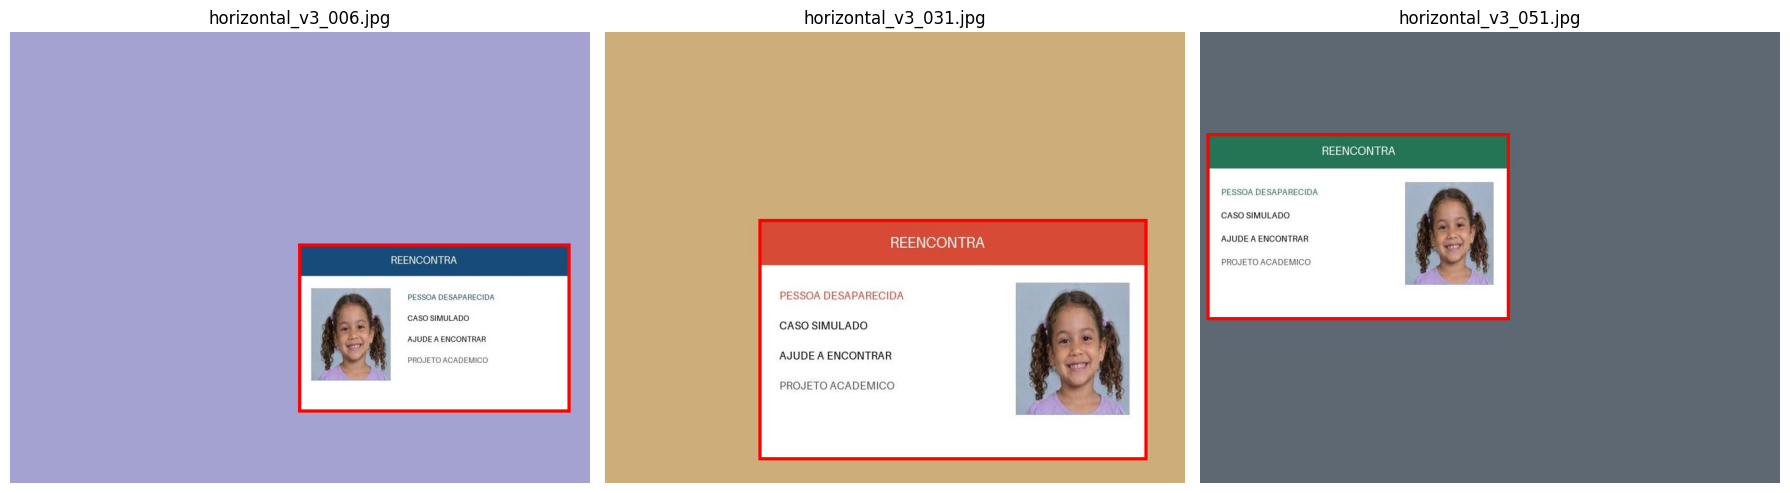

In [5]:
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import os
import random

pasta_imagens = "/content/dataset_v3/images/train"
pasta_labels = "/content/dataset_v3/labels/train"

# Selecionar 3 imagens horizontais
arquivos = [
    nome for nome in os.listdir(pasta_imagens)
    if nome.startswith("horizontal_v3_") and nome.endswith(".jpg")
]

random.seed(42)
selecionados = random.sample(arquivos, 3)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, nome in zip(axes, selecionados):
    imagem = Image.open(
        os.path.join(pasta_imagens, nome)
    ).convert("RGB")

    largura, altura = imagem.size
    desenho = ImageDraw.Draw(imagem)

    caminho_label = os.path.join(
        pasta_labels,
        nome.replace(".jpg", ".txt")
    )

    with open(caminho_label, "r") as arquivo:
        for linha in arquivo:
            classe, cx, cy, w, h = map(float, linha.split())

            x1 = (cx - w / 2) * largura
            y1 = (cy - h / 2) * altura
            x2 = (cx + w / 2) * largura
            y2 = (cy + h / 2) * altura

            desenho.rectangle(
                [x1, y1, x2, y2],
                outline="red",
                width=5
            )

    ax.imshow(imagem)
    ax.set_title(nome)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
%pip install -q ultralytics

from ultralytics import YOLO

# Carregar o modelo YOLO11 Nano
modelo_v3 = YOLO("yolo11n.pt")

# Iniciar treinamento
resultados_v3 = modelo_v3.train(
    data="/content/dataset_v3/data.yaml",
    epochs=20,
    imgsz=640,
    batch=8,
    device=0,
    project="/content/drive/MyDrive/Reencontra/treinamentos",
    name="yolo_cartazes_v3",
    exist_ok=True
)

print("Treinamento V3 concluído!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_v3/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fr

In [7]:
from ultralytics import YOLO
import os

caminho_modelo = (
    "/content/drive/MyDrive/Reencontra/"
    "treinamentos/yolo_cartazes_v3/weights/best.pt"
)

if os.path.exists(caminho_modelo):
    print("Modelo V3 encontrado!")

    modelo_v3 = YOLO(caminho_modelo)

    metricas = modelo_v3.val(
        data="/content/dataset_v3/data.yaml",
        imgsz=640,
        device=0
    )

    print("\nRESULTADOS DO YOLO V3")
    print(f"Precisão: {metricas.box.mp:.2%}")
    print(f"Recall: {metricas.box.mr:.2%}")
    print(f"mAP50: {metricas.box.map50:.2%}")
    print(f"mAP50-95: {metricas.box.map:.2%}")
else:
    print("Modelo V3 não encontrado!")

Modelo V3 encontrado!
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 651.2±157.3 MB/s, size: 21.5 KB)
val: Scanning /content/dataset_v3/labels/val.cache... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 5.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.4it/s 1.4s
                   all         20         20      0.997          1      0.995      0.995
Speed: 4.2ms preprocess, 11.6ms inference, 0.0ms loss, 3.7ms postprocess per image
Results saved to /content/runs/detect/val

RESULTADOS DO YOLO V3
Precisão: 99.75%
Recall: 100.00%
mAP50: 99.50%
mAP50-95: 99.50%


Cartazes detectados: 1
Confiança: 93.76%


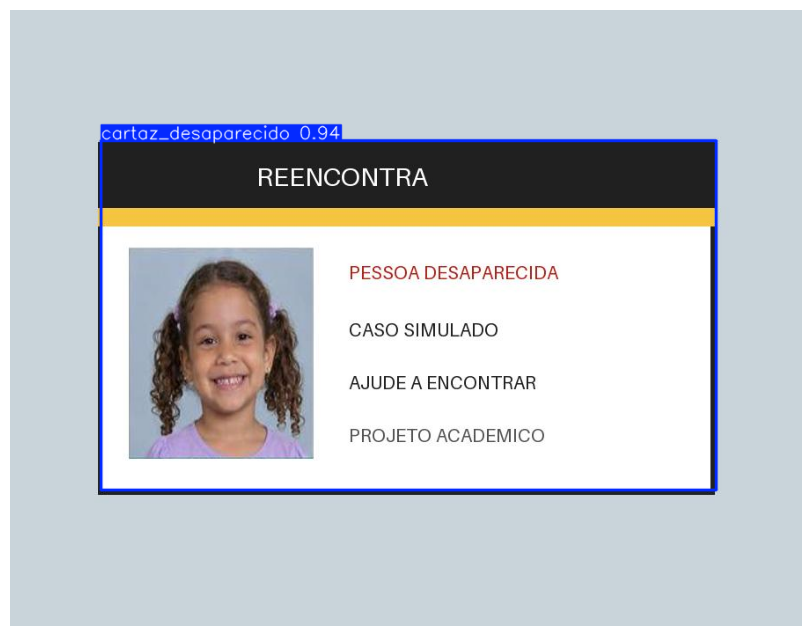

In [8]:
from ultralytics import YOLO
from PIL import Image
import matplotlib.pyplot as plt

modelo_v3 = YOLO(
    "/content/drive/MyDrive/Reencontra/"
    "treinamentos/yolo_cartazes_v3/weights/best.pt"
)

caminho_teste = (
    "/content/drive/MyDrive/Reencontra/"
    "testes/cartaz_horizontal_teste.jpg"
)

resultados = modelo_v3.predict(
    source=caminho_teste,
    conf=0.25,
    verbose=False
)

resultado = resultados[0]

print("Cartazes detectados:", len(resultado.boxes))

for caixa in resultado.boxes:
    print(
        "Confiança:",
        f"{float(caixa.conf[0]):.2%}"
    )

imagem = Image.fromarray(resultado.plot()[..., ::-1])

plt.figure(figsize=(12, 8))
plt.imshow(imagem)
plt.axis("off")
plt.show()

Cartazes detectados: 1
Confiança: 93.74%


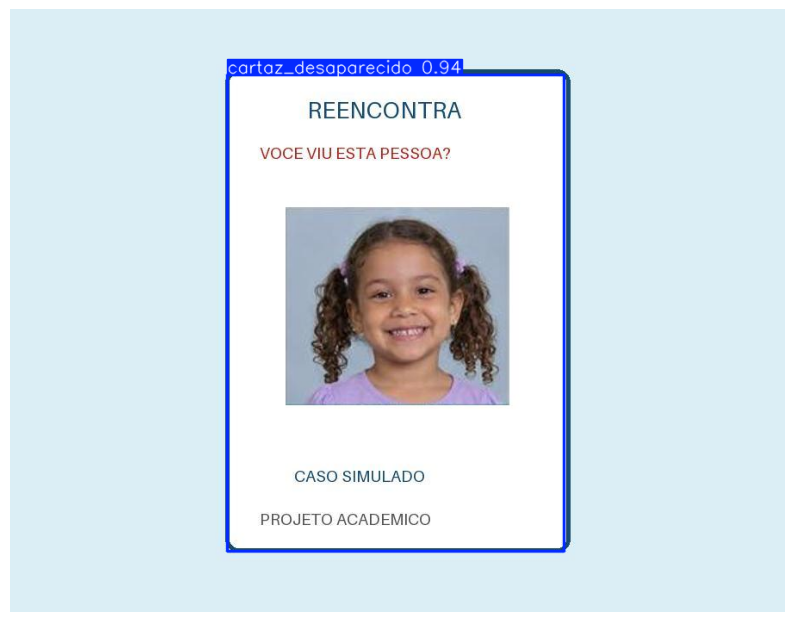

In [9]:
from PIL import Image
import matplotlib.pyplot as plt

caminho_vertical = (
    "/content/drive/MyDrive/Reencontra/"
    "testes/cartaz_reencontra_teste.jpg"
)

resultados = modelo_v3.predict(
    source=caminho_vertical,
    conf=0.25,
    verbose=False
)

resultado = resultados[0]

print("Cartazes detectados:", len(resultado.boxes))

for caixa in resultado.boxes:
    print(
        "Confiança:",
        f"{float(caixa.conf[0]):.2%}"
    )

imagem = Image.fromarray(
    resultado.plot()[..., ::-1]
)

plt.figure(figsize=(10, 8))
plt.imshow(imagem)
plt.axis("off")
plt.show()

In [10]:
import os

pasta_negativos = (
    "/content/drive/MyDrive/Reencontra/"
    "testes/negativos"
)

arquivos = sorted([
    os.path.join(pasta_negativos, nome)
    for nome in os.listdir(pasta_negativos)
    if nome.lower().endswith((".jpg", ".jpeg", ".png"))
])

total_deteccoes = 0

for caminho in arquivos:
    resultado = modelo_v3.predict(
        source=caminho,
        conf=0.25,
        verbose=False
    )[0]

    quantidade = len(resultado.boxes)
    total_deteccoes += quantidade

    print(
        f"{os.path.basename(caminho)}: "
        f"{quantidade} detecção(ões)"
    )

print("\nRESUMO")
print("Imagens negativas testadas:", len(arquivos))
print("Total de detecções indevidas:", total_deteccoes)

negativo_teste_000.jpg: 0 detecção(ões)
negativo_teste_001.jpg: 0 detecção(ões)
negativo_teste_002.jpg: 0 detecção(ões)
negativo_teste_003.jpg: 0 detecção(ões)
negativo_teste_004.jpg: 0 detecção(ões)

RESUMO
Imagens negativas testadas: 5
Total de detecções indevidas: 0


In [11]:
import os
import shutil

origem = (
    "/content/drive/MyDrive/Reencontra/"
    "treinamentos/yolo_cartazes_v3/weights/best.pt"
)

pasta_entrega = (
    "/content/drive/MyDrive/Reencontra/"
    "entrega_computer_vision"
)

os.makedirs(pasta_entrega, exist_ok=True)

destino = os.path.join(
    pasta_entrega,
    "reencontra_yolo_v3.pt"
)

shutil.copy2(origem, destino)

print("Modelo salvo:", os.path.exists(destino))
print(
    "Tamanho:",
    round(os.path.getsize(destino) / (1024 * 1024), 2),
    "MB"
)
print("Caminho:", destino)

Modelo salvo: True
Tamanho: 5.24 MB
Caminho: /content/drive/MyDrive/Reencontra/entrega_computer_vision/reencontra_yolo_v3.pt


In [12]:
import os

pasta_entrega = (
    "/content/drive/MyDrive/Reencontra/"
    "entrega_computer_vision"
)

codigo = '''from ultralytics import YOLO
import argparse

def main():
    parser = argparse.ArgumentParser(
        description="Detector de cartazes - Reencontra"
    )

    parser.add_argument(
        "--imagem",
        required=True,
        help="Caminho da imagem para análise"
    )

    parser.add_argument(
        "--modelo",
        default="reencontra_yolo_v3.pt",
        help="Caminho do modelo treinado"
    )

    args = parser.parse_args()

    modelo = YOLO(args.modelo)

    resultados = modelo.predict(
        source=args.imagem,
        conf=0.25,
        save=True
    )

    for resultado in resultados:
        print(
            "Cartazes detectados:",
            len(resultado.boxes)
        )

        for caixa in resultado.boxes:
            print(
                "Confiança:",
                f"{float(caixa.conf[0]):.2%}"
            )

if __name__ == "__main__":
    main()
'''

caminho_script = os.path.join(
    pasta_entrega,
    "detectar_cartazes.py"
)

with open(caminho_script, "w", encoding="utf-8") as arquivo:
    arquivo.write(codigo)

print("Script criado:", os.path.exists(caminho_script))
print("Arquivo:", caminho_script)

Script criado: True
Arquivo: /content/drive/MyDrive/Reencontra/entrega_computer_vision/detectar_cartazes.py


In [13]:
import subprocess

pasta = "/content/drive/MyDrive/Reencontra/entrega_computer_vision"

resultado = subprocess.run(
    [
        "python",
        f"{pasta}/detectar_cartazes.py",
        "--imagem",
        "/content/drive/MyDrive/Reencontra/testes/cartaz_horizontal_teste.jpg",
        "--modelo",
        f"{pasta}/reencontra_yolo_v3.pt"
    ],
    capture_output=True,
    text=True
)

print("Código de saída:", resultado.returncode)
print("\nSAÍDA:")
print(resultado.stdout)

if resultado.returncode != 0:
    print("\nERRO:")
    print(resultado.stderr[-3000:])

Código de saída: 0

SAÍDA:

image 1/1 /content/drive/MyDrive/Reencontra/testes/cartaz_horizontal_teste.jpg: 512x640 1 cartaz_desaparecido, 10.2ms
Speed: 43.1ms preprocess, 10.2ms inference, 15.5ms postprocess per image at shape (1, 3, 512, 640)
Results saved to /content/runs/detect/predict
Cartazes detectados: 1
Confiança: 93.76%



In [14]:
import os

pasta_entrega = (
    "/content/drive/MyDrive/Reencontra/"
    "entrega_computer_vision"
)

caminho = os.path.join(
    pasta_entrega,
    "requirements.txt"
)

dependencias = """ultralytics>=8.3,<9
Pillow>=10,<13
"""

with open(caminho, "w", encoding="utf-8") as arquivo:
    arquivo.write(dependencias)

print("requirements.txt criado:", os.path.exists(caminho))
print("\nConteúdo:")
print(open(caminho, encoding="utf-8").read())

requirements.txt criado: True

Conteúdo:
ultralytics>=8.3,<9
Pillow>=10,<13



In [16]:
from pathlib import Path

pasta = Path("/content/drive/MyDrive/Reencontra/entrega_computer_vision")
pasta.mkdir(parents=True, exist_ok=True)

readme = '''# Reencontra — Detecção de Cartazes com YOLO11

## Sobre o projeto

O Reencontra é um projeto acadêmico de tecnologia cidadã
voltado ao contexto de pessoas desaparecidas.

Este módulo utiliza visão computacional para detectar
cartazes de desaparecimento em imagens.

O sistema não realiza reconhecimento facial.

## Tecnologias

- Python
- Ultralytics YOLO11 Nano
- PyTorch
- Google Colab
- GPU NVIDIA T4

## Dataset

O treinamento V3 utilizou:

- 241 imagens de treinamento
- 20 imagens de validação
- Cartazes verticais e horizontais
- Exemplos negativos sem cartazes

Classe detectada: `cartaz_desaparecido`

O dataset foi produzido com imagens sintéticas.

## Resultados do YOLO V3

| Métrica | Resultado |
|---|---|
| Precisão | 99,75% |
| Recall | 100,00% |
| mAP50 | 99,50% |
| mAP50-95 | 99,50% |

Teste com cartaz horizontal:

- 1 cartaz detectado
- Confiança: 93,76%
- Tempo de inferência: 10,2 ms na GPU utilizada

## Instalação

Instale as dependências:

    pip install -r requirements.txt

## Execução

Coloque o modelo e o script na mesma pasta.

Execute:

    python detectar_cartazes.py --imagem cartaz_teste.jpg

O resultado visual será salvo em `runs/detect`.

## Arquivos

- `detectar_cartazes.py`: script de detecção
- `reencontra_yolo_v3.pt`: modelo treinado
- `requirements.txt`: dependências
- `README.md`: documentação

## Limitações

O treinamento e a validação utilizaram dados sintéticos,
com variedade limitada de fotografias e layouts.

As métricas não representam necessariamente o desempenho
em imagens reais.

O detector localiza cartazes, mas não identifica pessoas
nem verifica a veracidade das informações.

## Contexto acadêmico

Global Solution 2026.2 — FIAP

Applied Computer Vision — Projeto Reencontra.
'''

caminho = pasta / "README.md"

caminho.write_text(readme, encoding="utf-8")

print("README criado:", caminho.exists())
print("Tamanho:", caminho.stat().st_size, "bytes")

README criado: True
Tamanho: 1787 bytes


In [17]:
from pathlib import Path

pasta = Path(
    "/content/drive/MyDrive/Reencontra/entrega_computer_vision"
)

arquivos = [
    "detectar_cartazes.py",
    "reencontra_yolo_v3.pt",
    "requirements.txt",
    "README.md"
]

print("VERIFICAÇÃO DA ENTREGA\n")

tudo_certo = True

for nome in arquivos:
    caminho = pasta / nome

    if caminho.is_file() and caminho.stat().st_size > 0:
        tamanho = caminho.stat().st_size / 1024
        print(f"OK - {nome} ({tamanho:.2f} KB)")
    else:
        print(f"ERRO - {nome} não encontrado ou vazio")
        tudo_certo = False

print("\nEntrega completa:", tudo_certo)

VERIFICAÇÃO DA ENTREGA

OK - detectar_cartazes.py (0.88 KB)
OK - reencontra_yolo_v3.pt (5362.59 KB)
OK - requirements.txt (0.03 KB)
OK - README.md (1.75 KB)

Entrega completa: True


In [18]:
from pathlib import Path

pasta = Path("/content/drive/MyDrive")

notebooks = list(
    pasta.rglob("Reencontra_Computer_Vision.ipynb")
)

print("Notebooks encontrados:", len(notebooks))

for notebook in notebooks:
    print("Caminho:", notebook)
    print(
        "Tamanho:",
        round(notebook.stat().st_size / 1024, 2),
        "KB"
    )

Notebooks encontrados: 1
Caminho: /content/drive/MyDrive/Colab Notebooks/Reencontra_Computer_Vision.ipynb
Tamanho: 3751.77 KB
